In [1]:
import pandas as pd
import matplotlib.pyplot as plt
orders = pd.read_csv("olist_orders_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
order_reviews = pd.read_csv("olist_order_reviews_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")
geo = pd.read_csv("olist_geolocation_dataset.csv")
order_payments = pd.read_csv("olist_order_payments_dataset.csv")

# Convertir las columnas de fechas de orders

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

# 1. Línea: pedidos por mes
* Cargar orders y convertir order_purchase_timestamp a datetime.
* Filtrar order_status == 'delivered' (opcional).
* Crear columna de mes con .dt.to_period('M').
* Groupby por mes y contar order_id con nunique.
* Recortar meses extremos (2016 y sept–oct 2018 casi no tienen datos): buena lección de "mira tus datos antes de graficar".
* Graficar mes vs. número de pedidos; título, etiquetas y rotar ticks.


month
2016-09       1
2016-10     265
2016-12       1
2017-01     750
2017-02    1653
2017-03    2546
2017-04    2303
2017-05    3546
2017-06    3135
2017-07    3872
2017-08    4193
2017-09    4150
2017-10    4478
2017-11    7289
2017-12    5513
2018-01    7069
2018-02    6555
2018-03    7003
2018-04    6798
2018-05    6749
2018-06    6099
2018-07    6159
2018-08    6351
Freq: M, Name: order_id, dtype: int64

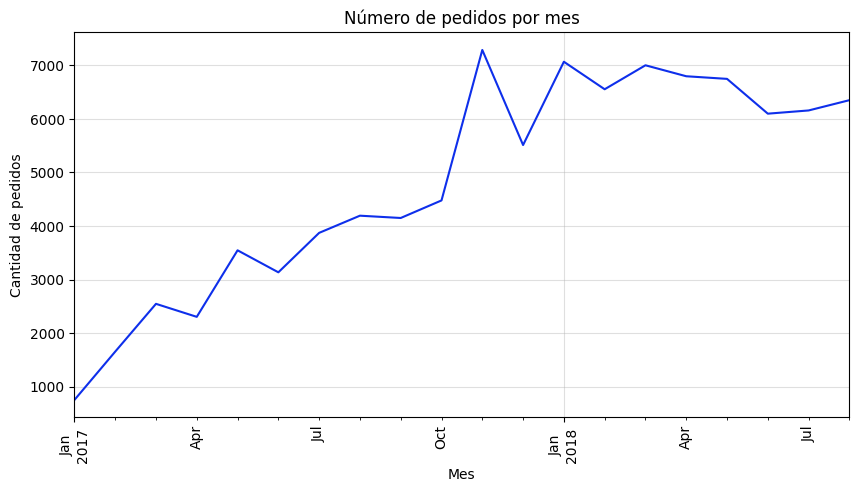

In [2]:
#solo pedidos entregados y solo las columnas que necesito
df1=orders[orders["order_status"]=="delivered"][["order_id","order_purchase_timestamp"]].copy()

#columna de mes a partir de la fecha de compra
df1["month"]=df1["order_purchase_timestamp"].dt.to_period("M")

#agrupar por mes y contar pedidos únicos
pedidos_por_mes=df1.groupby("month")["order_id"].nunique()
display(pedidos_por_mes) #mira tus datos antes de graficar: 2016 y sept-oct 2018 casi no tienen datos

#recorto los meses extremos
pedidos_por_mes=pedidos_por_mes.loc["2017-01":"2018-08"]

ax=pedidos_por_mes.plot(kind="line",
                        color="#0e2feb",
                        title="Número de pedidos por mes",
                        xlabel="Mes",
                        ylabel="Cantidad de pedidos",
                        rot=90,
                        figsize=(10,5)
                        )
plt.grid(alpha=0.4)
plt.show()


# 2. Barras horizontales: top 10 categorías por ingreso plt.barh
* Merge order_items + products por product_id.
* Merge con product_category_name_translation por product_category_name (nombres en inglés).
* Groupby categoría → suma de price.
* Tomar las 10 mayores con .nlargest(10).
* Invertir el orden para que la mayor quede arriba y graficar con barh.

product_category_name
ferramentas_jardim         485256.46
automotivo                 592720.11
utilidades_domesticas      632248.66
cool_stuff                 635290.85
moveis_decoracao           729762.49
informatica_acessorios     911954.32
esporte_lazer              988048.97
cama_mesa_banho           1036988.68
relogios_presentes        1205005.68
beleza_saude              1258681.34
Name: price, dtype: float64

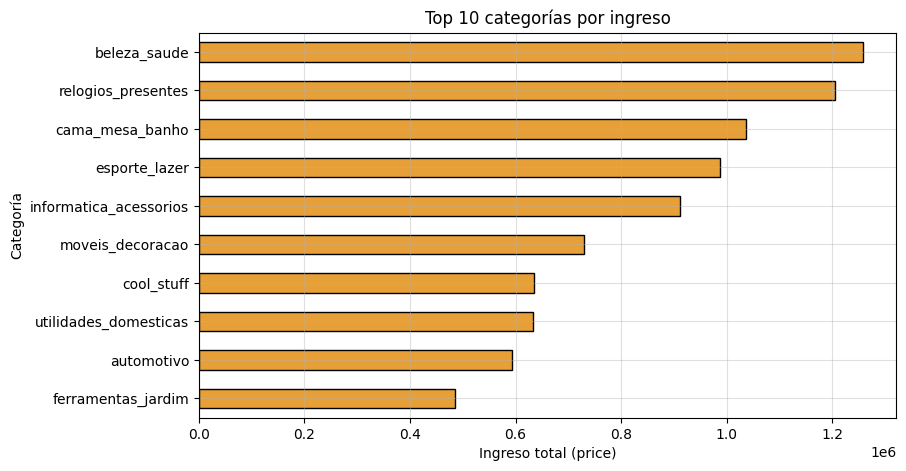

In [ ]:
#merge order_items + products por product_id
df2=order_items[["product_id","price"]].merge(products[["product_id","product_category_name"]],on="product_id")
#suma de price por categoría y me quedo con las 10 mayores
top10_ingreso=df2.groupby("product_category_name")["price"].sum().nlargest(10)

#sort_values() de menor a mayor para que la mayor quede arriba en barh
top10_ingreso=top10_ingreso.sort_values()
display(top10_ingreso)

ax=top10_ingreso.plot(kind="barh",
                      color="#e7a038",
                      edgecolor="black",
                      title="Top 10 categorías por ingreso",
                      xlabel="Ingreso total (price)",
                      ylabel="Categoría",
                      figsize=(9,5)
                      )
plt.grid(alpha=0.4)
plt.show()

# 3. Histograma: distribución del precio plt.hist
* Usar order_items['price'].
* Primer histograma directo: se verá muy sesgado.
* Repetir con bins en escala log o con np.log10(price).
* Discusión: por qué la media engaña. Marcar media y mediana con axvline.

Media: 120.65373901464716 Mediana: 74.99


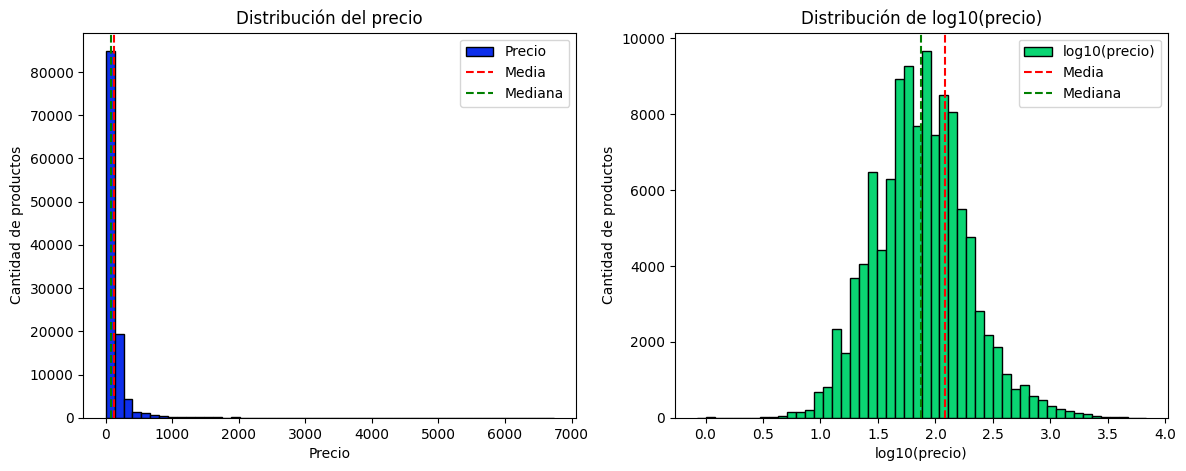

In [4]:
import numpy as np
precio=order_items["price"]
media=precio.mean()
mediana=precio.median()
print("Media:",media,"Mediana:",mediana)

fig, ax=plt.subplots(1,2,figsize=(14,5))

#histograma directo: muy sesgado
precio.plot(kind="hist",
            ax=ax[0],
            bins=50,
            color="#0e2feb",
            edgecolor="black",
            label="Precio",
            title="Distribución del precio"
            )
ax[0].axvline(media,color="red",linestyle="--",label="Media")
ax[0].axvline(mediana,color="green",linestyle="--",label="Mediana")
ax[0].set_xlabel("Precio")
ax[0].set_ylabel("Cantidad de productos")
ax[0].legend()

#con log10(price) la distribución se ve mucho más clara
np.log10(precio).plot(kind="hist",
                      ax=ax[1],
                      bins=50,
                      color="#0ad573",
                      edgecolor="black",
                      label="log10(precio)",
                      title="Distribución de log10(precio)"
                      )
ax[1].axvline(np.log10(media),color="red",linestyle="--",label="Media")
ax[1].axvline(np.log10(mediana),color="green",linestyle="--",label="Mediana")
ax[1].set_xlabel("log10(precio)")
ax[1].set_ylabel("Cantidad de productos")
ax[1].legend()
plt.show()

#Discusión: unos pocos productos muy caros jalan la media hacia arriba,
#por eso la media (~120) queda muy por encima de la mediana (~75) y "engaña".


# 4. Histograma comparativo: días de entrega reales vs. estimados hist + alpha
* En orders, convertir a datetime las columnas de compra, entrega real y entrega estimada.
* Calcular dias_reales = entregado − compra y dias_estimados = estimado − compra (en .dt.days).
* Eliminar NaN (pedidos no entregados).
* Dos histogramas en el mismo eje con alpha=0.5 y leyenda.

,dias_reales,dias_estimados
count,96476.000000,96476.000000
mean,12.094086,23.374228
std,9.551746,8.760830
min,0.000000,2.000000
25%,6.000000,18.000000
50%,10.000000,23.000000
75%,15.000000,28.000000
max,209.000000,155.000000


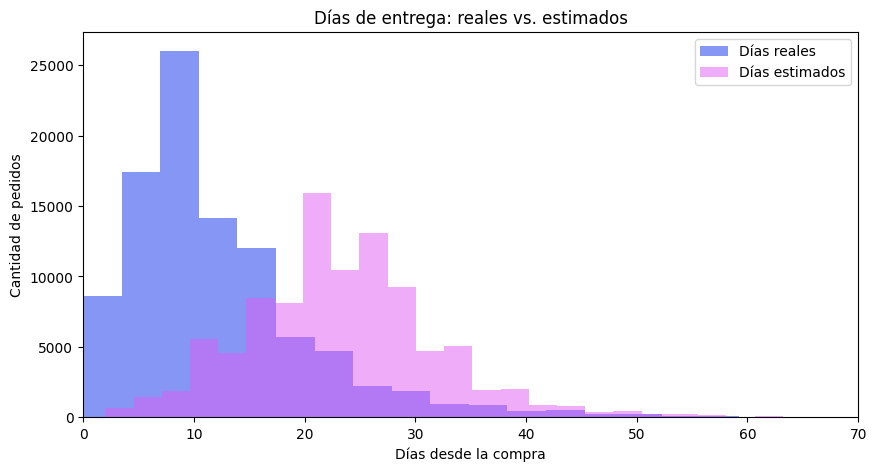

In [5]:
#me quedo solo con las 3 columnas de fechas y elimino los pedidos no entregados (NaN)
df4=orders[["order_purchase_timestamp","order_delivered_customer_date","order_estimated_delivery_date"]].dropna()

#días reales y días estimados (en número de días desde la compra)
df4["dias_reales"]=(df4["order_delivered_customer_date"]-df4["order_purchase_timestamp"]).dt.days
df4["dias_estimados"]=(df4["order_estimated_delivery_date"]-df4["order_purchase_timestamp"]).dt.days
display(df4[["dias_reales","dias_estimados"]].describe())

#dos histogramas en el mismo eje con alpha=0.5
fig, ax=plt.subplots(figsize=(10,5))
df4["dias_reales"].plot(kind="hist",
                        ax=ax,
                        alpha=0.5,
                        bins=60,
                        color="#0e2feb",
                        label="Días reales"
                        )
df4["dias_estimados"].plot(kind="hist",
                           ax=ax,
                           alpha=0.5,
                           bins=60,
                           color="#e05bf4",
                           label="Días estimados"
                           )
ax.set_xlim(0,70) #hay entregas de más de 100 días que estiran mucho el eje, las dejo fuera de la vista
ax.set_title("Días de entrega: reales vs. estimados")
ax.set_xlabel("Días desde la compra")
ax.set_ylabel("Cantidad de pedidos")
ax.legend()
plt.show()

# 5. Boxplot: calificación vs. días de retraso plt.boxplot
* En orders, calcular retraso = entregado − estimado en días.
* Merge con order_reviews por order_id (quitar duplicados por order_id: hay pedidos con más de una reseña).
* Agrupar el retraso por review_score (1–5) → lista de 5 arrays.
* Pasar la lista a boxplot con etiquetas 1–5.
* Conclusión esperada: las calificaciones de 1 tienen retrasos mucho mayores.

,order_id,order_delivered_customer_date,order_estimated_delivery_date,retraso,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-10 21:25:13,2017-10-18,-8,4
1,53cdb2fc8bc7dce0b6741e2150273451,2018-08-07 15:27:45,2018-08-13,-6,4
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-17 18:06:29,2018-09-04,-18,5
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-12-02 00:28:42,2017-12-15,-13,5
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-16 18:17:02,2018-02-26,-10,5


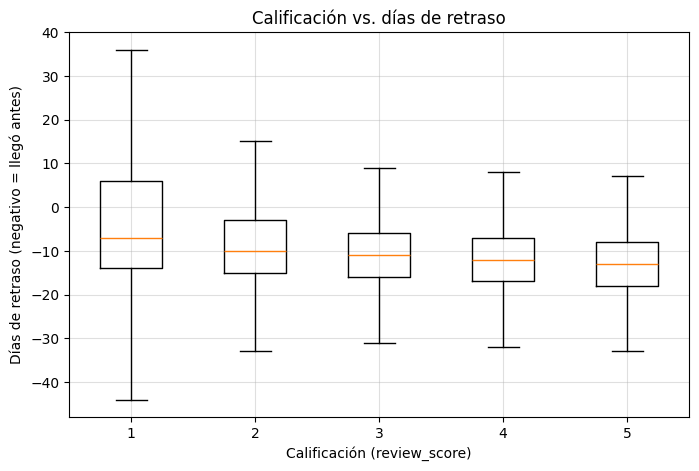

In [6]:
#retraso = entregado - estimado (positivo = llegó tarde, negativo = llegó antes)
df_ret=orders[["order_id","order_delivered_customer_date","order_estimated_delivery_date"]].dropna()
df_ret["retraso"]=(df_ret["order_delivered_customer_date"]-df_ret["order_estimated_delivery_date"]).dt.days

#hay pedidos con más de una reseña, me quedo con una por order_id
reviews=order_reviews[["order_id","review_score"]].drop_duplicates(subset="order_id")

#merge con las reseñas
df_ret=df_ret.merge(reviews,on="order_id")
display(df_ret.head())

#lista de 5 arrays: el retraso de cada calificación (1 a 5)
datos_box=[df_ret[df_ret["review_score"]==i]["retraso"] for i in range(1,6)]

fig, ax=plt.subplots(figsize=(8,5))
ax.boxplot(datos_box, showfliers=False) #showfliers=False oculta los valores extremos para ver mejor las cajas
ax.set_xticklabels([1,2,3,4,5])
ax.set_title("Calificación vs. días de retraso")
ax.set_xlabel("Calificación (review_score)")
ax.set_ylabel("Días de retraso (negativo = llegó antes)")
plt.grid(alpha=0.4)
plt.show()



# 6. Barras con error: calificación promedio a tiempo vs. tarde plt.bar(yerr=)
* Usar el mismo merge de la gráfica 5.
* Crear columna booleana tarde = retraso > 0.
* groupby('tarde') → mean y std de review_score.
* Graficar barras con yerr=std.

,mean,std
tarde,,
False,4.290582,1.149084
True,2.271702,1.571613


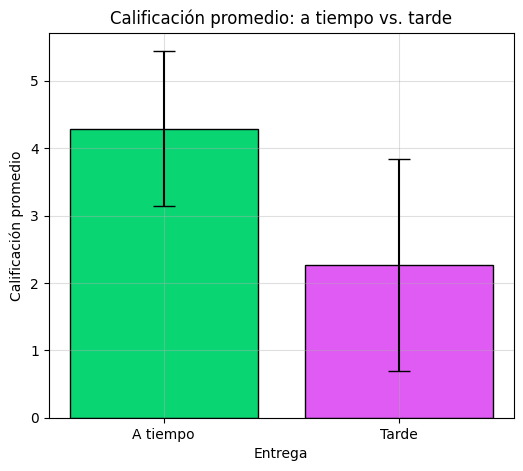

In [7]:
#columna booleana: True si llegó tarde
df_ret["tarde"]=df_ret["retraso"]>0

#promedio y desviación estándar de la calificación según llegó a tiempo o tarde
resumen=df_ret.groupby("tarde")["review_score"].agg(["mean","std"])
display(resumen)

fig, ax=plt.subplots(figsize=(6,5))
ax.bar(["A tiempo","Tarde"],
       resumen["mean"],
       yerr=resumen["std"],
       capsize=8,
       color=["#0ad573","#e05bf4"],
       edgecolor="black"
       )
ax.set_title("Calificación promedio: a tiempo vs. tarde")
ax.set_xlabel("Entrega")
ax.set_ylabel("Calificación promedio")
plt.grid(alpha=0.4)
plt.show()

# 7. Pastel/dona: métodos de pago plt.pie
* order_payments → value_counts() de payment_type.
* Agrupar not_defined y categorías pequeñas en "otros".
* Graficar con autopct='%1.1f%%'; para dona, wedgeprops={'width':0.4}.
* Discusión: por qué los pasteles suelen ser mala idea; comparar con la versión en barras.


payment_type
credit_card    76795
boleto         19784
voucher         5775
otros           1532
Name: count, dtype: int64

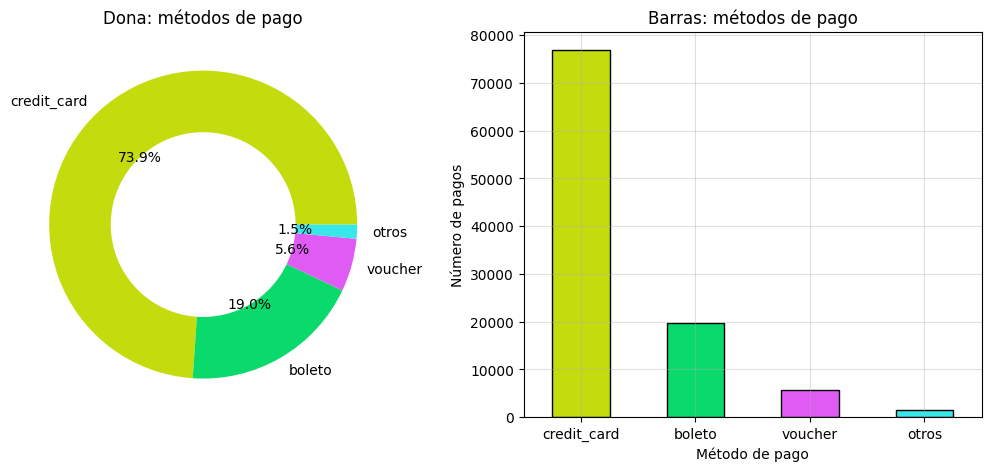

In [8]:
#cantidad de pagos por método
pagos=order_payments["payment_type"].value_counts()

#agrupo en "otros" los métodos que representan menos del 2% (incluye not_defined)
porcentaje=pagos/pagos.sum()
chicos=porcentaje[porcentaje<0.02].index
pagos_agrupado=pagos.drop(chicos)
pagos_agrupado["otros"]=pagos[chicos].sum()
display(pagos_agrupado)

fig, ax=plt.subplots(1,2,figsize=(13,5))

#dona (wedgeprops con width crea el hueco del centro)
pagos_agrupado.plot(kind="pie",
                    ax=ax[0],
                    autopct="%1.1f%%",
                    wedgeprops={"width":0.4},
                    colors=["#c4dc0d","#0ad96b","#e05bf4","#38e7ea"],
                    title="Dona: métodos de pago",
                    ylabel=""
                    )

#la misma información en barras para comparar
pagos_agrupado.plot(kind="bar",
                    ax=ax[1],
                    color=["#c4dc0d","#0ad96b","#e05bf4","#38e7ea"],
                    edgecolor="black",
                    title="Barras: métodos de pago",
                    xlabel="Método de pago",
                    ylabel="Número de pagos",
                    rot=0
                    )
ax[1].grid(alpha=0.4)
plt.show()

#Discusión: en el pastel es difícil comparar rebanadas pequeñas (voucher vs. otros),
#en las barras se comparan las alturas directamente.


# 8. Barras agrupadas: monto promedio por mensualidades y método de pago pivot + bar
* Tomar order_payments.
* Crear rangos de payment_installments con pd.cut: 1, 2–3, 4–6, 7–10, más de 10.
* pivot_table: index = rango, columns = payment_type, values = payment_value, aggfunc = 'mean'.
* Barras agrupadas desplazando cada serie con x + i*ancho (o df.plot(kind='bar')).

payment_type,boleto,credit_card,debit_card,voucher
rango,,,,
1,145.034435,95.872930,142.57017,65.703354
2-3,NaN,134.230429,NaN,NaN
4-6,NaN,181.318430,NaN,NaN
7-10,NaN,333.825551,NaN,NaN
Más de 10,NaN,358.344839,NaN,NaN


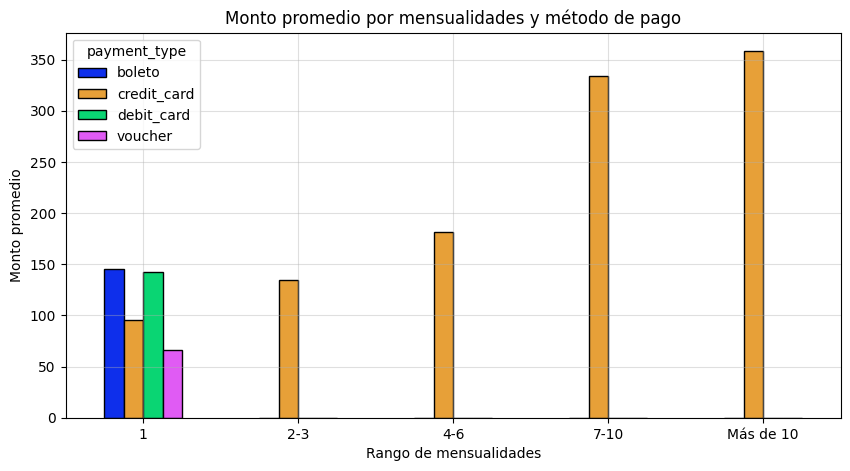

In [9]:
#me quedo con las columnas que necesito y quito not_defined (pagos de 0)
df8=order_payments[["payment_installments","payment_type","payment_value"]]
df8=df8[df8["payment_type"]!="not_defined"].copy()

#rangos de mensualidades: 1, 2-3, 4-6, 7-10, más de 10
df8["rango"]=pd.cut(df8["payment_installments"],
                    bins=[0,1,3,6,10,100],
                    labels=["1","2-3","4-6","7-10","Más de 10"]
                    )

#filas = rango, columnas = método de pago, valores = monto promedio
tabla8=df8.pivot_table(index="rango",
                       columns="payment_type",
                       values="payment_value",
                       aggfunc="mean",
                       observed=False)
display(tabla8)

#barras agrupadas con pandas
ax=tabla8.plot(kind="bar",
               color=["#0e2feb","#e7a038","#0ad573","#e05bf4"],
               edgecolor="black",
               title="Monto promedio por mensualidades y método de pago",
               xlabel="Rango de mensualidades",
               ylabel="Monto promedio",
               rot=0,
               figsize=(10,5)
               )
plt.grid(alpha=0.4)
plt.show()




# 9. Barras apiladas: estado del pedido por estado de la república pivot + bottom=
* Merge orders + customers por customer_id.
* pivot_table: index = customer_state, columns = order_status, values = order_id, aggfunc = 'count', fill_value=0.
* Normalizar por fila (dividir entre .sum(axis=1)) para tener porcentajes.
* Quedarse con los 10 estados con más pedidos.
* Apilar barras con un loop acumulando bottom.

order_status,approved,canceled,created,delivered,invoiced,processing,shipped,unavailable
customer_state,,,,,,,,
SP,0.00,0.78,0.00,97.02,0.38,0.33,0.79,0.70
RJ,0.00,0.67,0.01,96.09,0.20,0.25,2.25,0.53
MG,0.01,0.55,0.00,97.58,0.34,0.27,0.61,0.64
RS,0.00,0.46,0.02,97.79,0.37,0.26,0.68,0.44
PR,0.00,0.44,0.02,97.58,0.30,0.30,0.57,0.79
SC,0.00,0.52,0.00,97.50,0.33,0.38,0.77,0.49
BA,0.00,0.47,0.00,96.33,0.27,0.33,2.01,0.59
DF,0.00,0.33,0.05,97.20,0.14,0.33,1.40,0.56
ES,0.00,0.44,0.00,98.13,0.20,0.10,0.84,0.30


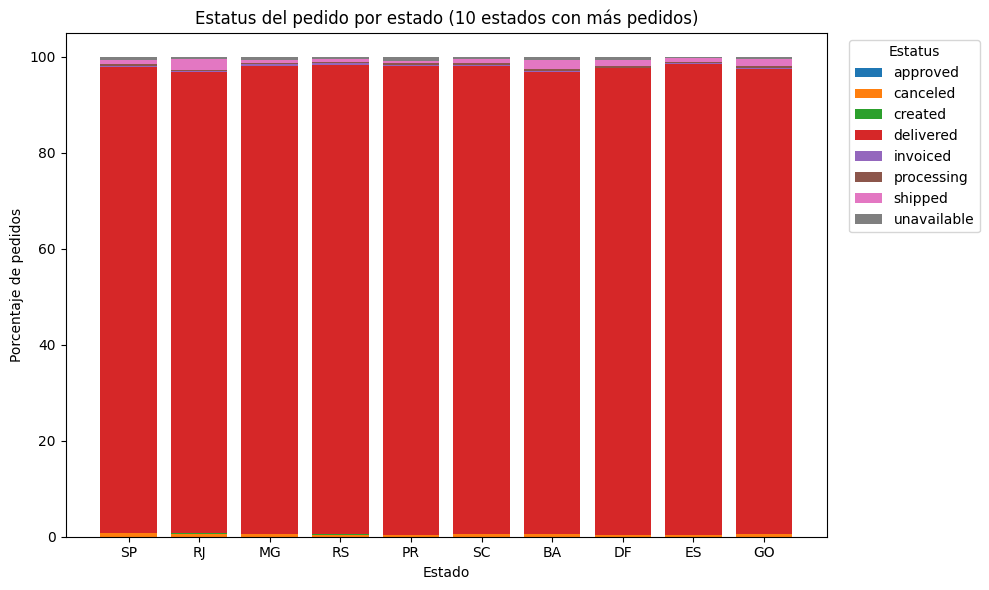

In [10]:
#merge orders + customers por customer_id
ord_cli=orders.merge(customers,on="customer_id")

#filas = estado, columnas = estatus del pedido, valores = cantidad de pedidos
tabla9=ord_cli.pivot_table(index="customer_state",
                           columns="order_status",
                           values="order_id",
                           aggfunc="count",
                           fill_value=0)

#me quedo con los 10 estados con más pedidos
top10_estados=tabla9.sum(axis=1).nlargest(10).index
tabla9=tabla9.loc[top10_estados]

#normalizo por fila: cada estado suma 100%
porcentajes=tabla9.div(tabla9.sum(axis=1),axis=0)*100
display(porcentajes.round(2))

#apilo las barras con un loop acumulando bottom
fig, ax=plt.subplots(figsize=(10,6))
base=np.zeros(len(porcentajes))
for estatus in porcentajes.columns:
    ax.bar(porcentajes.index,
           porcentajes[estatus],
           bottom=base,
           label=estatus)
    base=base+porcentajes[estatus].values

ax.set_title("Estatus del pedido por estado (10 estados con más pedidos)")
ax.set_xlabel("Estado")
ax.set_ylabel("Porcentaje de pedidos")
ax.legend(title="Estatus",bbox_to_anchor=(1.02,1),loc="upper left")
plt.tight_layout()
plt.show()



Quitando delivered, que es casi el 97 % de los pedidos.

order_status,approved,canceled,created,invoiced,processing,shipped,unavailable
customer_state,,,,,,,
SP,0.08,26.27,0.08,12.85,10.92,26.35,23.45
RJ,0.00,17.13,0.20,5.18,6.37,57.57,13.55
MG,0.36,22.78,0.00,13.88,11.03,25.27,26.69
RS,0.00,20.66,0.83,16.53,11.57,30.58,19.83
PR,0.00,18.03,0.82,12.30,12.30,23.77,32.79
SC,0.00,20.88,0.00,13.19,15.38,30.77,19.78
BA,0.00,12.90,0.00,7.26,8.87,54.84,16.13
DF,0.00,11.67,1.67,5.00,11.67,50.00,20.00
ES,0.00,23.68,0.00,10.53,5.26,44.74,15.79


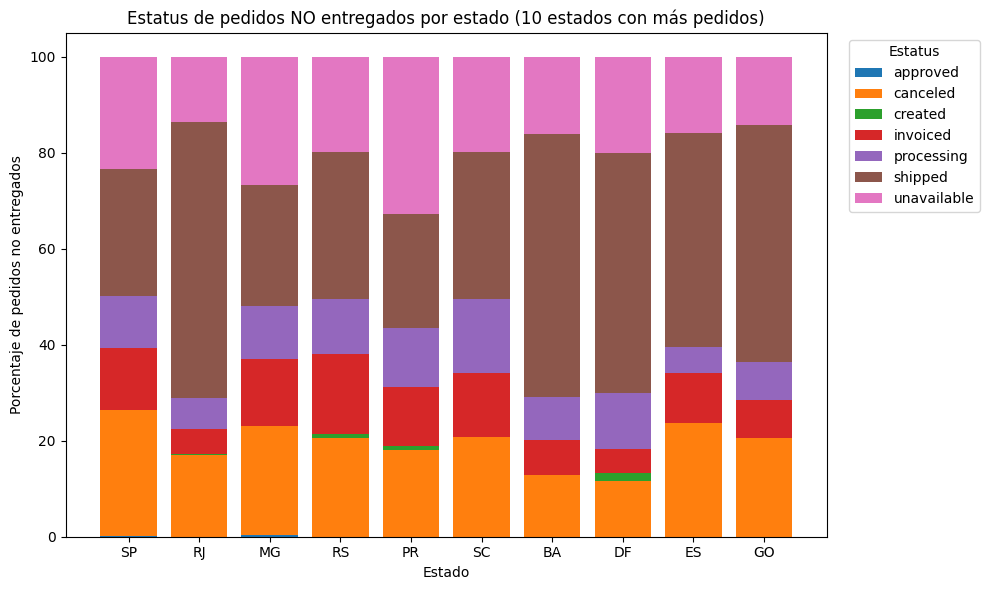

In [11]:
#merge orders + customers por customer_id
ord_cli=orders.merge(customers,on="customer_id")

#filas = estado, columnas = estatus del pedido, valores = cantidad de pedidos
tabla9=ord_cli.pivot_table(index="customer_state",
                           columns="order_status",
                           values="order_id",
                           aggfunc="count",
                           fill_value=0)

#los 10 estados con más pedidos (se calcula con TODOS los estatus)
top10_estados=tabla9.sum(axis=1).nlargest(10).index
tabla9=tabla9.loc[top10_estados]

#quito "delivered" (casi 97% de los pedidos) para que se vean los demás estatus
tabla9=tabla9.drop(columns="delivered")

#normalizo por fila: ahora cada estado suma 100% de pedidos NO entregados
porcentajes=tabla9.div(tabla9.sum(axis=1),axis=0)*100
display(porcentajes.round(2))

#apilo las barras con un loop acumulando bottom
fig, ax=plt.subplots(figsize=(10,6))
base=np.zeros(len(porcentajes))
for estatus in porcentajes.columns:
    ax.bar(porcentajes.index,
           porcentajes[estatus],
           bottom=base,
           label=estatus)
    base=base+porcentajes[estatus].values

ax.set_title("Estatus de pedidos NO entregados por estado (10 estados con más pedidos)")
ax.set_xlabel("Estado")
ax.set_ylabel("Porcentaje de pedidos no entregados")
ax.legend(title="Estatus",bbox_to_anchor=(1.02,1),loc="upper left")
plt.tight_layout()
plt.show()

# 10. Dispersión: peso del producto vs. costo de envío plt.scatter
* Merge order_items + products por product_id.
* Tomar product_weight_g y freight_value; quitar NaN.
* Muestrear con .sample(3000) (110k puntos saturan la gráfica).
* Graficar con alpha bajo; opcionalmente ejes en escala log.
* Extra: colorear por price con c= y agregar plt.colorbar().

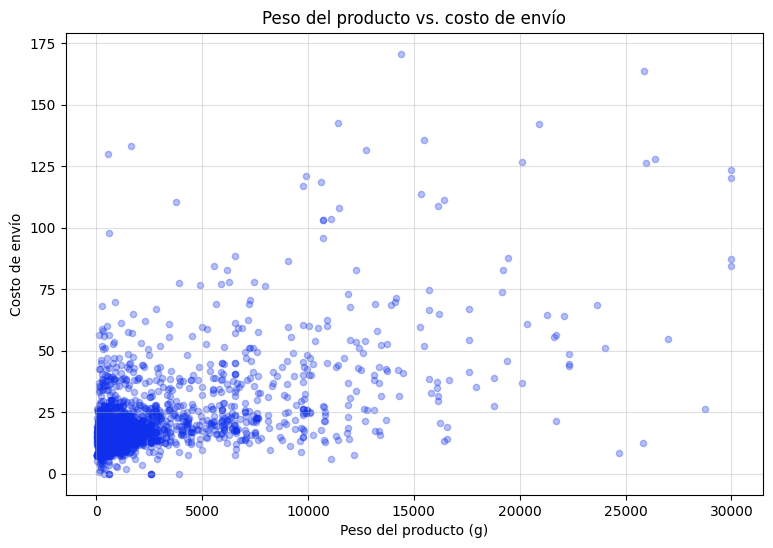

In [12]:
#merge order_items + products por product_id
df10=order_items.merge(products,on="product_id")

#peso, flete y precio sin NaN
datos10=df10[["product_weight_g","freight_value","price"]].dropna()

#muestra de 3000 puntos (110k saturan la gráfica)
muestra=datos10.sample(3000,random_state=42)

#dispersión con alpha bajo
ax=muestra.plot(kind="scatter",
                x="product_weight_g",
                y="freight_value",
                color="#0e2feb",
                alpha=0.3,
                title="Peso del producto vs. costo de envío",
                xlabel="Peso del producto (g)",
                ylabel="Costo de envío",
                figsize=(9,6)
                )
plt.grid(alpha=0.4)
plt.show()

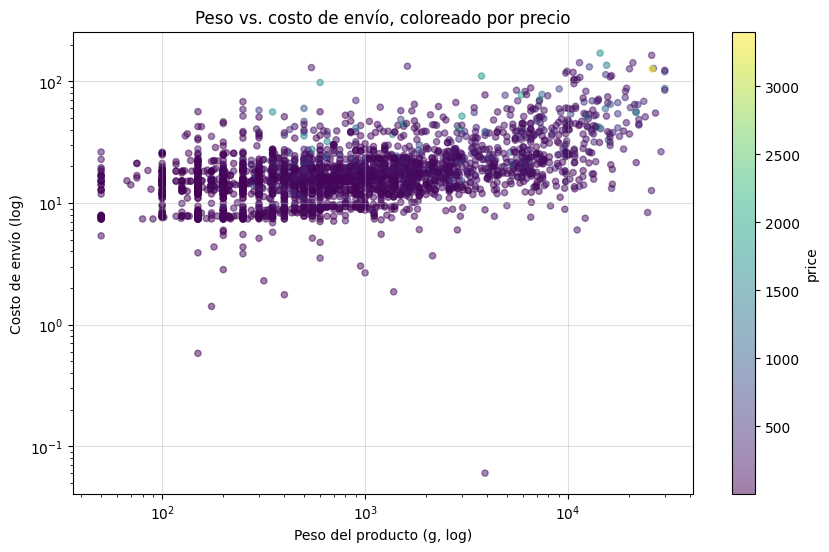

In [13]:
#escala log (quito ceros porque el log de 0 no existe) y color por precio
muestra_log=muestra[(muestra["product_weight_g"]>0)&(muestra["freight_value"]>0)]
ax=muestra_log.plot(kind="scatter",
                    x="product_weight_g",
                    y="freight_value",
                    c="price",
                    cmap="viridis",
                    alpha=0.5,
                    logx=True,
                    logy=True,
                    title="Peso vs. costo de envío, coloreado por precio",
                    xlabel="Peso del producto (g, log)",
                    ylabel="Costo de envío (log)",
                    figsize=(10,6)
                    )
plt.grid(alpha=0.4)
plt.show()

# 11. Mapa de calor: pedidos por día de la semana × hora pivot + imshow
* De order_purchase_timestamp extraer .dt.dayofweek y .dt.hour.
* pivot_table: index = día, columns = hora, values = order_id, aggfunc = 'count'.
* plt.imshow(pivot, aspect='auto', cmap='YlOrRd').
* Etiquetas Lun–Dom en y, 0–23 en x; agregar colorbar.
* Extra: escribir valores en las celdas con doble loop de ax.text.

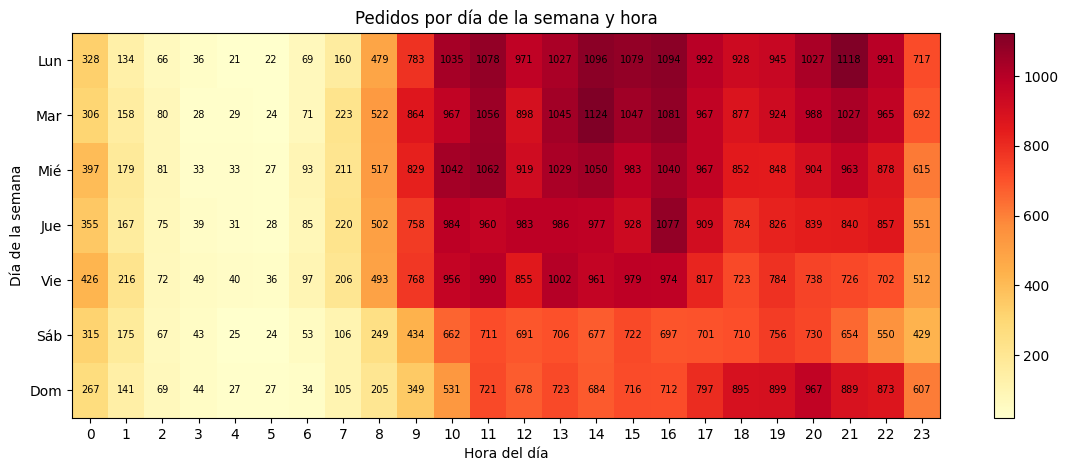

In [14]:
#día de la semana (0=Lun ... 6=Dom) y hora (0-23)
df11=orders[["order_id","order_purchase_timestamp"]].copy()
df11["dia"]=df11["order_purchase_timestamp"].dt.dayofweek
df11["hora"]=df11["order_purchase_timestamp"].dt.hour

#filas = día, columnas = hora, valores = cantidad de pedidos
pivot11=df11.pivot_table(index="dia",
                         columns="hora",
                         values="order_id",
                         aggfunc="count")

fig, ax=plt.subplots(figsize=(14,5))
im=ax.imshow(pivot11, aspect="auto", cmap="YlOrRd")

ax.set_yticks(range(7))
ax.set_yticklabels(["Lun","Mar","Mié","Jue","Vie","Sáb","Dom"])
ax.set_xticks(range(24))
ax.set_xticklabels(range(24))
ax.set_title("Pedidos por día de la semana y hora")
ax.set_xlabel("Hora del día")
ax.set_ylabel("Día de la semana")
plt.colorbar(im)

#Extra: valor dentro de cada celda
for i in range(7):
    for j in range(24):
        ax.text(j, i, pivot11.iloc[i,j], ha="center", va="center", fontsize=7)

plt.show()

# 12. Dashboard final: subplots + doble eje plt.subplots + twinx
* Reutilizar los dataframes de las gráficas 1, 2, 5 y 11.
* fig, axes = plt.subplots(2, 2, figsize=(14,10)).
* Panel 1: pedidos por mes y, con twinx(), ingreso mensual en el segundo eje (merge orders + order_items, groupby mes, suma de price).
* Demás paneles: top categorías, boxplot de reseñas y heatmap.
* fig.suptitle, plt.tight_layout() y savefig('dashboard.png', dpi=150).

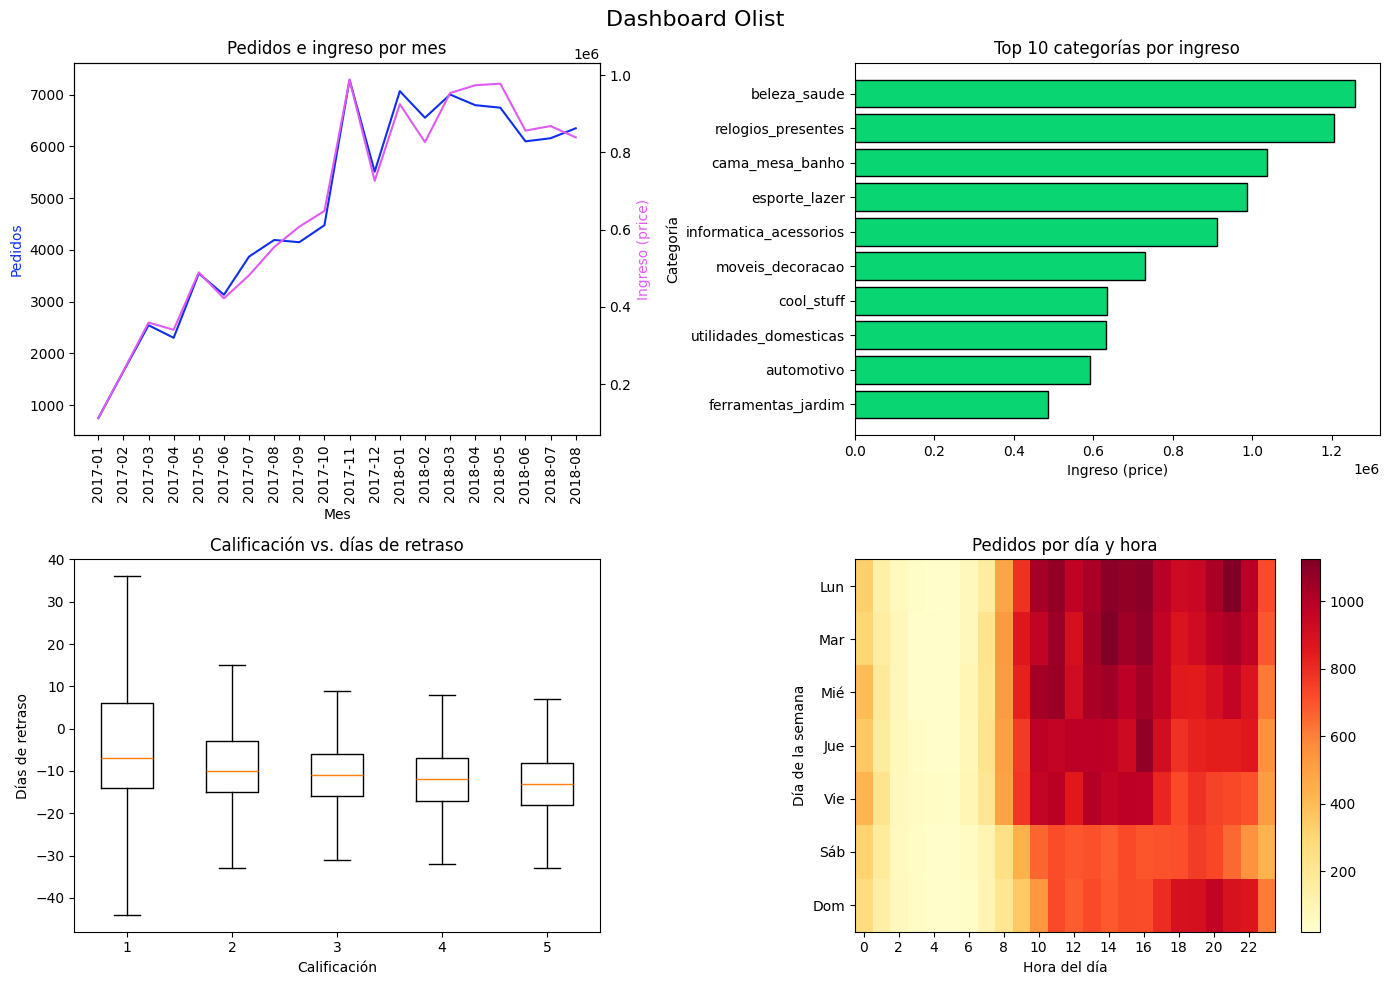

In [15]:
#Panel 1: pedidos por mes e ingreso mensual (solo pedidos entregados)
entregados=orders[orders["order_status"]=="delivered"][["order_id","order_purchase_timestamp"]].copy()
entregados["mes"]=entregados["order_purchase_timestamp"].dt.to_period("M")

pedidos_mes=entregados.groupby("mes")["order_id"].nunique()

items_mes=order_items[["order_id","price"]].merge(entregados[["order_id","mes"]],on="order_id")
ingreso_mes=items_mes.groupby("mes")["price"].sum()

#recorto los meses extremos (casi no tienen datos)
pedidos_mes=pedidos_mes.loc["2017-01":"2018-08"]
ingreso_mes=ingreso_mes.loc["2017-01":"2018-08"]

#Panel 2: top 10 categorías por ingreso
cat=order_items[["product_id","price"]].merge(products[["product_id","product_category_name"]],on="product_id")
top_cat=cat.groupby("product_category_name")["price"].sum().nlargest(10).sort_values()

#Panel 4: heatmap día x hora
mapa=orders.copy()
mapa["dia"]=mapa["order_purchase_timestamp"].dt.dayofweek
mapa["hora"]=mapa["order_purchase_timestamp"].dt.hour
pivot_calor=mapa.pivot_table(index="dia",columns="hora",values="order_id",aggfunc="count")

#Dashboard 2x2
fig, axes=plt.subplots(2,2,figsize=(14,10))

#Panel 1: línea + segundo eje con twinx
axes[0,0].plot(pedidos_mes.index.astype(str), pedidos_mes.values, color="#0e2feb")
axes[0,0].set_title("Pedidos e ingreso por mes")
axes[0,0].set_xlabel("Mes")
axes[0,0].set_ylabel("Pedidos",color="#0e2feb")
axes[0,0].tick_params(axis="x",rotation=90)
eje2=axes[0,0].twinx()
eje2.plot(ingreso_mes.index.astype(str), ingreso_mes.values, color="#e05bf4")
eje2.set_ylabel("Ingreso (price)",color="#e05bf4")

#Panel 2: barras horizontales
axes[0,1].barh(top_cat.index, top_cat.values, color="#0ad573", edgecolor="black")
axes[0,1].set_title("Top 10 categorías por ingreso")
axes[0,1].set_xlabel("Ingreso (price)")
axes[0,1].set_ylabel("Categoría")

#Panel 3: boxplot de reseñas (datos_box viene del ejercicio 5)
axes[1,0].boxplot(datos_box, showfliers=False)
axes[1,0].set_xticklabels([1,2,3,4,5])
axes[1,0].set_title("Calificación vs. días de retraso")
axes[1,0].set_xlabel("Calificación")
axes[1,0].set_ylabel("Días de retraso")

#Panel 4: heatmap
im=axes[1,1].imshow(pivot_calor, aspect="auto", cmap="YlOrRd")
axes[1,1].set_yticks(range(7))
axes[1,1].set_yticklabels(["Lun","Mar","Mié","Jue","Vie","Sáb","Dom"])
axes[1,1].set_xticks(range(0,24,2))
axes[1,1].set_title("Pedidos por día y hora")
axes[1,1].set_xlabel("Hora del día")
axes[1,1].set_ylabel("Día de la semana")
fig.colorbar(im, ax=axes[1,1])

fig.suptitle("Dashboard Olist", fontsize=16)
plt.tight_layout()
plt.savefig("dashboard.png", dpi=150)
plt.show()